# Capstone B — TeleConnect: Customer Churn Analysis
**Python for Full Stack Data Science with AI & Generative AI · Naresh IT · Lead Trainer: Ajit Byru**

**The client.** TeleConnect loses about a quarter of its customers a year and replaces each at four times the cost of keeping one. The VP Customer has a table of ~7,000 customers and one question: **who is leaving, and what do they have in common?** She needs a one-page brief for the board — not a model.

**Rules:** no `sklearn`; every cleaning decision logged with rows and a reason; every answer a chart plus one sentence; the brief is one page for someone who will never open this notebook.

1. Business Problem
2. Show raw CSV/data
3. Rows vs Columns
4. Load into pandas
5. Inspect the daatset
6. Show the data quality problems
7. Build the data quality log
8. Cleaning each problem
9. Save clean data - separately
10. Calculations - Calculate churn rate
churn by contract, churn by plan, churn rate
11. Compare / constrast using null hypothesis
churners vs stayers
t-test
cohne's d
categorical analysis
crosstab
chi-square
segment size vs churn rate
12. Use graphical method for showcasing
13. Build the  write up of the solution - Executive brief
14. What did you solve ?
...
Which of the current customers will leave next? Predictive Analysis ML

---
## Session 1 — Load, profile, clean

### 1.1 Load and profile
`shape`, `info`, `describe`, nulls, duplicates. Then look at the *values* in `churned`, `tenure_months`, `monthly_charges`, `city` — the types are wrong for a reason.

In [56]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import ttest_ind, chi2_contingency
sns.set_theme(style="whitegrid"); rng = np.random.default_rng(7)
raw = pd.read_csv("customers_2025.csv")
print(raw.shape); raw.info()

(7085, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7085 entries, 0 to 7084
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customer_id      7085 non-null   object 
 1   city             7085 non-null   object 
 2   age              7085 non-null   int64  
 3   gender           7085 non-null   object 
 4   tenure_months    7085 non-null   object 
 5   plan_type        7085 non-null   object 
 6   contract         7085 non-null   object 
 7   monthly_charges  7085 non-null   object 
 8   total_charges    6869 non-null   float64
 9   support_calls    7085 non-null   int64  
 10  payment_method   7085 non-null   object 
 11  has_broadband    7085 non-null   bool   
 12  has_streaming    7085 non-null   bool   
 13  churned          7085 non-null   object 
dtypes: bool(2), float64(1), int64(2), object(9)
memory usage: 678.2+ KB


In [57]:
# YOUR CODE HERE
# Hint: isna().sum(), duplicated().sum(), churned value_counts, samples of tenure_months / monthly_charges, unique cities, age min/max
print("\nNulls:")
print(raw.isna().sum())

print("\nDuplicate rows:", raw.duplicated().sum())
print("\nDuplicate customer IDs:", raw["customer_id"].duplicated().sum())

print("\nChurn encodings:")
print(raw["churned"].value_counts(dropna=False))

print("\nTenure examples:")
print(raw["tenure_months"].astype(str).value_counts().head(10))

print("\nMonthly-charge examples:")
print(
    raw["monthly_charges"]
    .astype(str)
    .sample(10, random_state=7)
    .tolist()
)

print("\nCities:")
print(sorted(raw["city"].unique()))

print("\nAge range:", raw["age"].min(), "to", raw["age"].max())


Nulls:
customer_id          0
city                 0
age                  0
gender               0
tenure_months        0
plan_type            0
contract             0
monthly_charges      0
total_charges      216
support_calls        0
payment_method       0
has_broadband        0
has_streaming        0
churned              0
dtype: int64

Duplicate rows: 85

Duplicate customer IDs: 85

Churn encodings:
churned
No     4977
Yes    1395
no      321
0       216
1        90
yes      86
Name: count, dtype: int64

Tenure examples:
tenure_months
12    155
30    155
34    153
25    150
37    150
13    150
38    149
22    147
6     144
23    144
Name: count, dtype: int64

Monthly-charge examples:
['867.0', '1630.0', '₹712', '1037.0', '1169.0', '813.0', '₹594', '700.0', '₹667', '1051.0']

Cities:
['BENGALURU', 'Bengaluru', 'CHENNAI', 'Chennai', 'HYDERABAD', 'Hyderabad', 'KOCHI', 'Kochi', 'PUNE', 'Pune']

Age range: -5 to 212


### 📝 Data-Quality Log (graded)

| # | Problem | Rows | Fix | Why this fix |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |
| 5 | | | | |
| 6 | | | | |
| 7 | | | | |

### 1.2 Duplicates

In [58]:
# YOUR CODE HERE
# Hint: drop_duplicates(); print removed
before = len(raw)

raw = raw.drop_duplicates().copy()

removed_duplicates = before - len(raw)

print("Duplicate rows removed:", removed_duplicates)
print("Shape after duplicate removal:", raw.shape)

Duplicate rows removed: 85
Shape after duplicate removal: (7000, 14)


### 1.3 `churned` — three encodings of one yes/no
Standardise to a single boolean. Count each encoding first so the log has numbers.

In [59]:
# YOUR CODE HERE
# Hint: value_counts first; then .astype(str).str.strip().str.lower().map({...}) to boolean; check no NaN
print("Before standardisation:")
print(raw["churned"].value_counts(dropna=False))

churn_map = {
    "yes": True,
    "no": False,
    "1": True,
    "0": False
}

raw["churned"] = (
    raw["churned"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map(churn_map)
)

assert raw["churned"].notna().all(), "Unexpected churn encoding remains."

print("\nAfter standardisation:")
print(raw["churned"].value_counts(dropna=False))

Before standardisation:
churned
No     4918
Yes    1382
no      316
0       211
1        89
yes      84
Name: count, dtype: int64

After standardisation:
churned
False    5445
True     1555
Name: count, dtype: int64


### 1.4 `monthly_charges` — text with a currency symbol on some rows

In [60]:
# YOUR CODE HERE
# Hint: count rows containing '₹'; str.replace, pd.to_numeric(errors='coerce')
currency_rows = (
    raw["monthly_charges"]
    .astype(str)
    .str.contains("₹", regex=False)
    .sum()
)

raw["monthly_charges"] = pd.to_numeric(
    raw["monthly_charges"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

print("Rows originally containing ₹:", currency_rows)

print(
    "Missing monthly_charges after conversion:",
    raw["monthly_charges"].isna().sum()
)

assert raw["monthly_charges"].notna().all()

Rows originally containing ₹: 560
Missing monthly_charges after conversion: 0


### 1.5 `tenure_months` — some rows are in years (`'2.5y'`)
Convert to months. Don't drop: tenure is the most important column in the file.

In [61]:
# YOUR CODE HERE
# Hint: mask = str.endswith('y'); years*12 else to_numeric; astype(int)
s = raw["tenure_months"].astype(str).str.strip()

year_mask = s.str.endswith("y")

raw["tenure_months"] = np.where(
    year_mask,
    pd.to_numeric(s.str[:-1], errors="coerce") * 12,
    pd.to_numeric(s, errors="coerce")
)

assert raw["tenure_months"].notna().all()

raw["tenure_months"] = (
    np.floor(raw["tenure_months"])
    .astype(int)
)

print("Rows converted from years:", year_mask.sum())

print(raw["tenure_months"].describe())

Rows converted from years: 420
count    7000.000000
mean       28.572286
std        18.053569
min         1.000000
25%        14.000000
50%        26.000000
75%        38.000000
max        71.000000
Name: tenure_months, dtype: float64


### 1.6 Impossible ages, city casing

In [62]:
# YOUR CODE HERE
# Hint: (age <= 0) | (age > 110) -> drop; city .str.title()
bad_age = (
    (raw["age"] <= 0) |
    (raw["age"] > 110)
)

print(
    "Impossible-age rows removed:",
    bad_age.sum()
)

raw = raw.loc[~bad_age].copy()

raw["city"] = (
    raw["city"]
    .astype(str)
    .str.strip()
    .str.title()
)

print(
    "Cities after standardisation:",
    sorted(raw["city"].unique())
)

Impossible-age rows removed: 4
Cities after standardisation: ['Bengaluru', 'Chennai', 'Hyderabad', 'Kochi', 'Pune']


### 1.7 Missing `total_charges`
🔮 **PREDICT:** `total_charges ≈ monthly_charges × tenure_months`. Is that a better fill than the median?

In [63]:
# YOUR CODE HERE
# Hint: check corr(total, monthly*tenure) on complete rows; fill missing with the product
complete = raw.loc[
    raw["total_charges"].notna()
].copy()

expected_total = (
    complete["monthly_charges"] *
    complete["tenure_months"]
)

corr = complete["total_charges"].corr(
    expected_total
)

print(
    "Correlation of observed total_charges with "
    "monthly_charges × tenure_months:",
    round(corr, 4)
)

missing_total = raw["total_charges"].isna().sum()

raw.loc[
    raw["total_charges"].isna(),
    "total_charges"
] = (
    raw.loc[
        raw["total_charges"].isna(),
        "monthly_charges"
    ]
    *
    raw.loc[
        raw["total_charges"].isna(),
        "tenure_months"
    ]
)

print(
    "Missing total_charges filled:",
    missing_total
)

print(
    "Remaining missing total_charges:",
    raw["total_charges"].isna().sum()
)

Correlation of observed total_charges with monthly_charges × tenure_months: 0.9997
Missing total_charges filled: 209
Remaining missing total_charges: 0


### 1.8 Save and accept
Print the final shape, the churn rate, and the mean tenure. Save `customers_clean.csv`.

In [64]:
# YOUR CODE HERE
# Hint: shape, churn rate, mean tenure; to_csv('customers_clean.csv')
df = raw.copy()

print("Final shape:", df.shape)

print(
    "Churn rate:",
    f"{df['churned'].mean():.4%}"
)

print(
    "Mean tenure (months):",
    f"{df['tenure_months'].mean():.2f}"
)

df.to_csv(
    "customers_clean.csv",
    index=False
)

print("Saved: customers_clean.csv")

Final shape: (6996, 14)
Churn rate: 22.2270%
Mean tenure (months): 28.57


Saved: customers_clean.csv


---
## Session 2 — Questions 1–4

### Q1. Churn rate — overall and by contract, plan, city
**Reading:** where is churn concentrated, and how big is the gap between the best and worst segment?

In [65]:
# YOUR CODE HERE
# Hint: df['churned'].mean(); groupby(col)['churned'].mean() for contract/plan_type/city; three barplots
overall_churn = df["churned"].mean()

print(
    f"Overall churn: {overall_churn:.2%}"
)

for col in [
    "contract",
    "plan_type",
    "city"
]:
    
    summary = (
        df.groupby(col)["churned"]
        .agg(["mean", "count", "sum"])
        .sort_values(
            "mean",
            ascending=False
        )
    )
    
    print(f"\n{col}")
    print(summary)

Overall churn: 22.23%

contract
                    mean  count   sum
contract                             
Month-to-month  0.356579   3800  1355
One year        0.080870   1793   145
Two year        0.039202   1403    55

plan_type
               mean  count  sum
plan_type                      
Premium    0.242012   1471  356
Basic      0.225956   2797  632
Standard   0.207845   2728  567

city
               mean  count  sum
city                           
Bengaluru  0.226696   1813  411
Chennai    0.224595   1358  305
Hyderabad  0.222115   2071  460
Pune       0.219559   1043  229
Kochi      0.210970    711  150


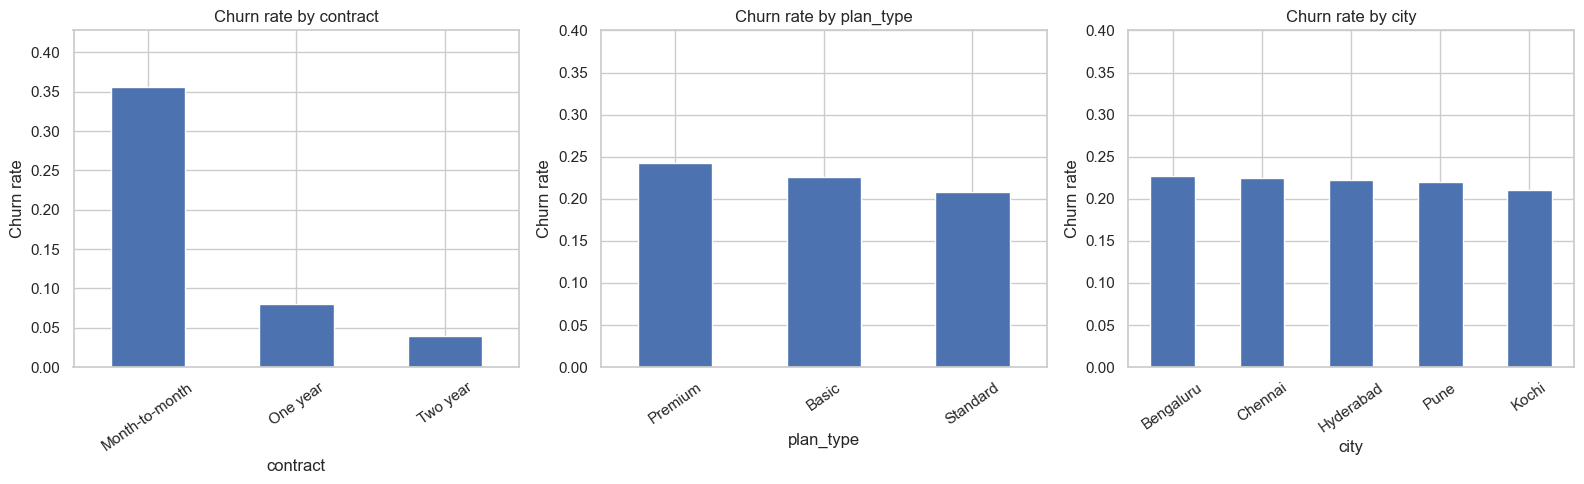

In [66]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

for ax, col in zip(
    axes,
    ["contract", "plan_type", "city"]
):
    
    rates = (
        df.groupby(col)["churned"]
        .mean()
        .sort_values(
            ascending=False
        )
    )
    
    rates.plot(
        kind="bar",
        ax=ax
    )
    
    ax.set_title(
        f"Churn rate by {col}"
    )
    
    ax.set_ylabel(
        "Churn rate"
    )
    
    ax.set_ylim(
        0,
        max(
            rates.max() * 1.2,
            0.4
        )
    )
    
    ax.tick_params(
        axis="x",
        rotation=35
    )

plt.tight_layout()
plt.show()

*Reading:*

### Q2. Which numbers differ between churners and stayers?
For each numeric column: mean for churners vs stayers, Cohen's d, and a test (shuffle or `ttest_ind`). Rank by |d|. **Reading:** which two numbers matter most, and which is noise?

In [67]:
# YOUR CODE HERE
# Hint: for each numeric col: means, Cohen's d, ttest_ind; DataFrame sorted by |d|; two boxplots
numeric_cols = [
    "age",
    "tenure_months",
    "monthly_charges",
    "total_charges",
    "support_calls"
]

rows = []

for col in numeric_cols:

    churners = (
        df.loc[
            df["churned"],
            col
        ]
        .dropna()
    )

    stayers = (
        df.loc[
            ~df["churned"],
            col
        ]
        .dropna()
    )

    pooled_sd = np.sqrt(
        (
            (len(churners) - 1)
            * churners.var(ddof=1)
            +
            (len(stayers) - 1)
            * stayers.var(ddof=1)
        )
        /
        (
            len(churners)
            +
            len(stayers)
            -
            2
        )
    )

    d = (
        churners.mean()
        -
        stayers.mean()
    ) / pooled_sd

    t_stat, p_value = ttest_ind(
        churners,
        stayers,
        equal_var=False,
        nan_policy="omit"
    )

    rows.append({
        "feature": col,
        "churner_mean": churners.mean(),
        "stayer_mean": stayers.mean(),
        "cohens_d": d,
        "abs_d": abs(d),
        "t_stat": t_stat,
        "p_value": p_value
    })

q2 = (
    pd.DataFrame(rows)
    .sort_values(
        "abs_d",
        ascending=False
    )
)

print(
    q2.round(4)
    .to_string(index=False)
)

        feature  churner_mean  stayer_mean  cohens_d  abs_d   t_stat  p_value
  tenure_months       18.7968      31.3613   -0.7270 0.7270 -30.8513    0.000
  total_charges    16752.0804   27957.3611   -0.5923 0.5923 -25.1461    0.000
  support_calls        1.5768       1.1128    0.4330 0.4330  13.8685    0.000
monthly_charges      900.3196     915.1671   -0.0434 0.0434  -1.4764    0.140
            age       45.4277      46.1173   -0.0419 0.0419  -1.4578    0.145


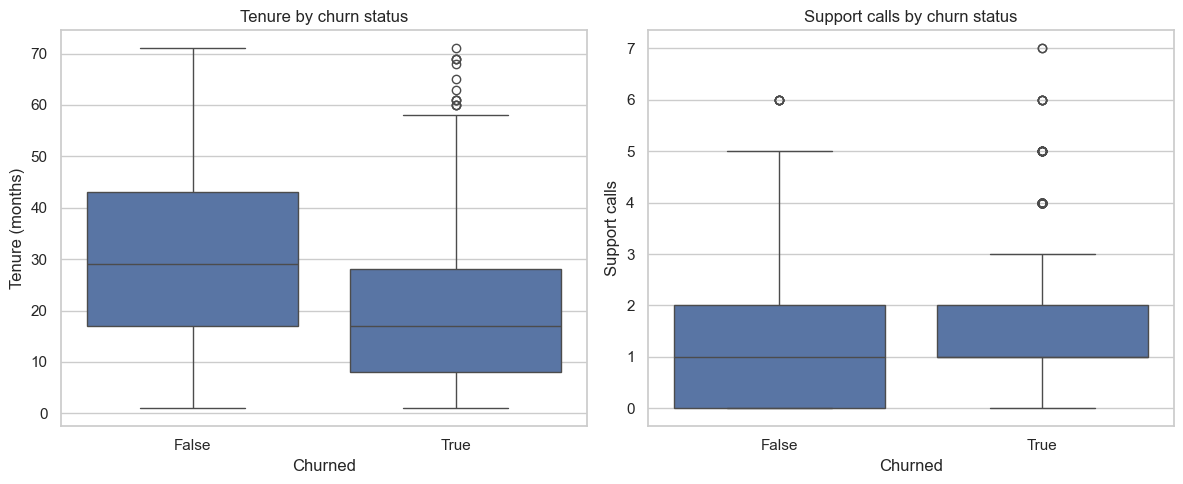

In [68]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

sns.boxplot(
    data=df,
    x="churned",
    y="tenure_months",
    ax=axes[0]
)

axes[0].set_title(
    "Tenure by churn status"
)

axes[0].set_xlabel(
    "Churned"
)

axes[0].set_ylabel(
    "Tenure (months)"
)


sns.boxplot(
    data=df,
    x="churned",
    y="support_calls",
    ax=axes[1]
)

axes[1].set_title(
    "Support calls by churn status"
)

axes[1].set_xlabel(
    "Churned"
)

axes[1].set_ylabel(
    "Support calls"
)

plt.tight_layout()
plt.show()

*Reading:*

### Q3. Which categories are associated with churn?
`pd.crosstab` per categorical column with churn rate per level, and `chi2_contingency` for the test. **Reading:** which category has the biggest spread in churn rate across its levels?

In [69]:
# YOUR CODE HERE
# Hint: pd.crosstab(df[col], df['churned']); chi2_contingency; churn rate spread per feature
categorical_cols = [
    "gender",
    "plan_type",
    "contract",
    "payment_method",
    "city",
    "has_broadband",
    "has_streaming"
]

q3_rows = []

q3_tables = {}

for col in categorical_cols:

    table = pd.crosstab(
        df[col],
        df["churned"]
    )

    q3_tables[col] = table

    chi2, p_value, dof, expected = (
        chi2_contingency(table)
    )

    rates = (
        df.groupby(col)["churned"]
        .mean()
    )

    q3_rows.append({
        "feature": col,
        "rate_spread":
            rates.max() - rates.min(),
        "chi2": chi2,
        "dof": dof,
        "p_value": p_value
    })

    print(
        f"\n--- {col} ---"
    )

    print(
        "Contingency table:"
    )

    print(table)

    print(
        "Churn rates:"
    )

    print(
        rates.round(4)
    )

    print(
        f"Chi-square={chi2:.3f}, "
        f"dof={dof}, "
        f"p={p_value:.4g}"
    )


q3 = (
    pd.DataFrame(q3_rows)
    .sort_values(
        "rate_spread",
        ascending=False
    )
)

print(
    "\nRanked by churn-rate spread:"
)

print(
    q3.round(4)
    .to_string(index=False)
)


--- gender ---
Contingency table:
churned  False  True 
gender               
F         2696    786
M         2745    769
Churn rates:
gender
F    0.2257
M    0.2188
Name: churned, dtype: float64
Chi-square=0.442, dof=1, p=0.5063

--- plan_type ---
Contingency table:
churned    False  True 
plan_type              
Basic       2165    632
Premium     1115    356
Standard    2161    567
Churn rates:
plan_type
Basic       0.2260
Premium     0.2420
Standard    0.2078
Name: churned, dtype: float64
Chi-square=6.820, dof=2, p=0.03303

--- contract ---
Contingency table:
churned         False  True 
contract                    
Month-to-month   2445   1355
One year         1648    145
Two year         1348     55
Churn rates:
contract
Month-to-month    0.3566
One year          0.0809
Two year          0.0392
Name: churned, dtype: float64
Chi-square=875.922, dof=2, p=6.252e-191

--- payment_method ---
Contingency table:
churned         False  True 
payment_method              
Bank transfer   

*Reading:*

### Q4. Churn by tenure cohort
Bins 0–6, 7–12, 13–24, 25+ months. Bar chart of churn rate per cohort. **Reading:** when is the customer most at risk, and what does that say about onboarding?

In [70]:
# YOUR CODE HERE
# Hint: pd.cut(tenure, bins=[0,6,12,24,999]); groupby cohort churn rate; barplot
bins = [
    0,
    6,
    12,
    24,
    np.inf
]

labels = [
    "0–6",
    "7–12",
    "13–24",
    "25+"
]

df["tenure_cohort"] = pd.cut(
    df["tenure_months"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

q4 = (
    df.groupby(
        "tenure_cohort",
        observed=True
    )["churned"]
    .agg([
        "mean",
        "count",
        "sum"
    ])
)

print(q4)

                   mean  count  sum
tenure_cohort                      
0–6            0.466877    634  296
7–12           0.320904    885  284
13–24          0.269585   1736  468
25+            0.135525   3741  507


*Reading:*

---
## Session 3 — Q5, Q6, the brief

### Q5. The highest-risk profile, in plain English
Combine the top findings into one segment (e.g. month-to-month + tenure ≤ 6 + 2+ support calls). Report its size, its churn rate, and how many churners it accounts for. **Reading:** is it where the retention budget should go?

In [71]:
# YOUR CODE HERE
# Hint: boolean mask for the segment; size, churn rate, share of all churners
categorical_cols = [
    "gender",
    "plan_type",
    "contract",
    "payment_method",
    "city",
    "has_broadband",
    "has_streaming"
]

q3_rows = []

q3_tables = {}

for col in categorical_cols:

    table = pd.crosstab(
        df[col],
        df["churned"]
    )

    q3_tables[col] = table

    chi2, p_value, dof, expected = (
        chi2_contingency(table)
    )

    rates = (
        df.groupby(col)["churned"]
        .mean()
    )

    q3_rows.append({
        "feature": col,
        "rate_spread":
            rates.max() - rates.min(),
        "chi2": chi2,
        "dof": dof,
        "p_value": p_value
    })

    print(
        f"\n--- {col} ---"
    )

    print(
        "Contingency table:"
    )

    print(table)

    print(
        "Churn rates:"
    )

    print(
        rates.round(4)
    )

    print(
        f"Chi-square={chi2:.3f}, "
        f"dof={dof}, "
        f"p={p_value:.4g}"
    )


q3 = (
    pd.DataFrame(q3_rows)
    .sort_values(
        "rate_spread",
        ascending=False
    )
)

print(
    "\nRanked by churn-rate spread:"
)

print(
    q3.round(4)
    .to_string(index=False)
)


--- gender ---
Contingency table:
churned  False  True 
gender               
F         2696    786
M         2745    769
Churn rates:
gender
F    0.2257
M    0.2188
Name: churned, dtype: float64
Chi-square=0.442, dof=1, p=0.5063

--- plan_type ---
Contingency table:
churned    False  True 
plan_type              
Basic       2165    632
Premium     1115    356
Standard    2161    567
Churn rates:
plan_type
Basic       0.2260
Premium     0.2420
Standard    0.2078
Name: churned, dtype: float64
Chi-square=6.820, dof=2, p=0.03303

--- contract ---
Contingency table:
churned         False  True 
contract                    
Month-to-month   2445   1355
One year         1648    145
Two year         1348     55
Churn rates:
contract
Month-to-month    0.3566
One year          0.0809
Two year          0.0392
Name: churned, dtype: float64
Chi-square=875.922, dof=2, p=6.252e-191

--- payment_method ---
Contingency table:
churned         False  True 
payment_method              
Bank transfer   

In [72]:
risk_mask = (
    df["contract"].eq(
        "Month-to-month"
    )
    &
    df["tenure_months"].le(6)
    &
    df["support_calls"].ge(2)
)

segment = df.loc[risk_mask]

segment_size = len(segment)

segment_churners = int(
    segment["churned"].sum()
)

segment_rate = (
    segment["churned"].mean()
)

segment_share = (
    segment_churners /
    df["churned"].sum()
)

print(
    "Segment: Month-to-month + "
    "tenure ≤ 6 months + 2+ support calls"
)

print(
    "Segment size:",
    segment_size
)

print(
    "Segment churn rate:",
    f"{segment_rate:.2%}"
)

print(
    "Churners in segment:",
    segment_churners
)

print(
    "Share of all churners:",
    f"{segment_share:.2%}"
)

print(
    "\nContext: total customers =",
    len(df),
    "| total churners =",
    int(df["churned"].sum())
)

Segment: Month-to-month + tenure ≤ 6 months + 2+ support calls
Segment size: 213
Segment churn rate: 62.44%
Churners in segment: 133
Share of all churners: 8.55%

Context: total customers = 6996 | total churners = 1555


*Reading:*

### Q6. Your own question
Options: does churn rise with monthly charges *within* a plan? · are support calls a cause or a symptom (do they rise with tenure)? · payment method × contract interaction · streaming add-on and retention · city differences after controlling for contract mix.

In [73]:
# YOUR CODE HERE
# Hint: your question, your code
# Q6 — Are support calls a cause or a symptom?

from scipy.stats import spearmanr


rho, p_value = spearmanr(
    df["support_calls"],
    df["tenure_months"]
)

print(
    f"Spearman correlation "
    f"(support_calls, tenure_months): "
    f"rho={rho:.4f}, p={p_value:.4f}"
)

Spearman correlation (support_calls, tenure_months): rho=-0.0040, p=0.7376


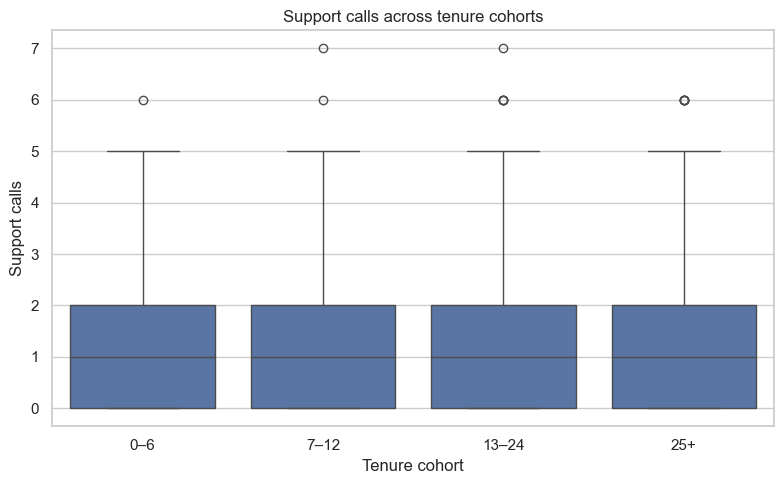

In [74]:
plt.figure(
    figsize=(8, 5)
)

sns.boxplot(
    data=df,
    x="tenure_cohort",
    y="support_calls"
)

plt.title(
    "Support calls across tenure cohorts"
)

plt.xlabel(
    "Tenure cohort"
)

plt.ylabel(
    "Support calls"
)

plt.tight_layout()

plt.show()

In [75]:
print(
    "Interpretation: support calls are essentially "
    "unrelated to tenure in this dataset."
)

print(
    "Therefore, tenure alone does not support a "
    "'calls are simply caused by being new' explanation."
)

print(
    "Causality would require longitudinal/timestamped "
    "data and a design that controls for confounding."
)

Interpretation: support calls are essentially unrelated to tenure in this dataset.
Therefore, tenure alone does not support a 'calls are simply caused by being new' explanation.
Causality would require longitudinal/timestamped data and a design that controls for confounding.


### The one-page churn brief (for the VP)
Structure: **Situation** (2 lines) → **Three findings**, each with the number → **Recommendation** (where the budget goes, what to change) → **Confidence** (one line: what you'd need to be surer).

> *Your brief here — 250–350 words.*

### Cliffhanger
You can describe who churned. The VP asks: "Which of the current 5,400 customers will churn next quarter?" — Module 20, on this exact file.